Title: “EDA: events, calendar and uncertainty

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
df = pd.read_csv(ROOT / "data/processed/data_daily_base.csv", parse_dates=["date"])

# 1. Weekend/holiday events: move them to the next fixing (otherwise they get lost)
EVENTS = ["is_ecb_decision_day", "is_rbi_decision_day", "is_fomc_decision_day",
          "is_us_cpi_day", "is_us_jobs_day", "is_india_budget_day"]
fix_block = df["eur_inr"].notna()[::-1].cumsum()[::-1]
df[EVENTS] = df.groupby(fix_block)[EVENTS].transform("max")

# 2. Keep only fixing days, from 8 Jan 2020
fx = df[df["eur_inr"].notna() & (df["date"] >= "2020-02-01")].reset_index(drop=True)

# 3. What we study: the daily change of EUR/INR (%) and its size
fx["chg_pct"] = fx["eur_inr"].pct_change() * 100
fx["abs_chg"] = fx["chg_pct"].abs()

# 4. Conclusions only from 2020-2024
train = fx[fx["date"] < "2024-01-01"]

print(fx.shape, train.shape)
print(fx[EVENTS].sum())

(1728, 58) (1005, 58)
is_ecb_decision_day     54
is_rbi_decision_day     42
is_fomc_decision_day    55
is_us_cpi_day           85
is_us_jobs_day          83
is_india_budget_day      8
dtype: int64


## 1. First look at my columns (2020–2024)

In [2]:
MY_COLS = ["gpr", "us_epu", "gpr_india", "in_epu", "eu_epu",
           "weekday", "day_of_month", "month", "is_de_holiday", "is_in_holiday",
           "is_payday_window", "is_diwali", "is_december", "is_india_fy_end",
           *EVENTS, "last_ecb_decision_bp", "last_rbi_decision_bp", "last_fomc_decision_bp"]

print(train[MY_COLS].describe().T[["count", "mean", "min", "max"]].round(2))
print("\nMissing values:", int(train[MY_COLS].isna().sum().sum()))
print(train[["chg_pct", "abs_chg"]].describe().round(3))

                        count    mean     min     max
gpr                    1005.0  109.73    8.32  540.83
us_epu                 1005.0  185.14   14.69  861.10
gpr_india              1005.0    0.25    0.09    0.51
in_epu                 1005.0   78.64   23.35  167.75
eu_epu                 1005.0  271.64  141.39  418.62
weekday                1005.0    2.00    0.00    4.00
day_of_month           1005.0   15.77    1.00   31.00
month                  1005.0    6.66    1.00   12.00
is_de_holiday          1005.0    0.01    0.00    1.00
is_in_holiday          1005.0    0.05    0.00    1.00
is_payday_window       1005.0    0.14    0.00    1.00
is_diwali              1005.0    0.00    0.00    1.00
is_december            1005.0    0.08    0.00    1.00
is_india_fy_end        1005.0    0.02    0.00    1.00
is_ecb_decision_day    1005.0    0.03    0.00    1.00
is_rbi_decision_day    1005.0    0.02    0.00    1.00
is_fomc_decision_day   1005.0    0.03    0.00    1.00
is_us_cpi_day          1005.

## Data quality: all 23 columns complete, values real and in plausible ranges.
## Target: a typical day moves 0.33% (≈ ₹150 per €500), with roughly as many up days as down days.
## Uncertainty: different scales, noisy daily indices (US EPU swung from 11 to 1,026 in two days), and Monday values may be low because of Sunday news. Test ## smoothing.
## Rare flags: Diwali (3), budget (6), German holidays (13). Too few to trust.
## Decision sizes: use them as categories (after a hike / cut / hold), not as averages.

## 2. Events: is EUR/INR wilder on or after event days?

Normal day (no event): 0.349 %  (830 days)
                    days  same day  next fixing
event                                          
ECB decision          31     0.356        0.491
RBI decision          25     0.355        0.249
Fed decision          32     0.343        0.519
US inflation (CPI)    51     0.320        0.439
US jobs report        48     0.431        0.480
India budget           4     0.542        0.675


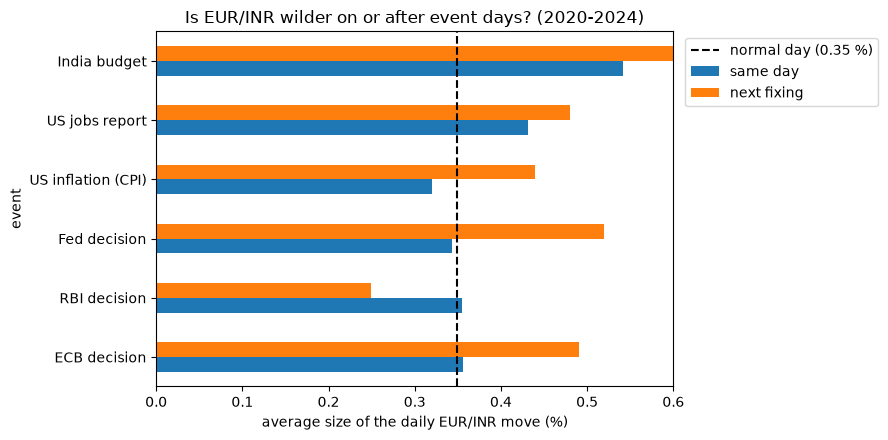

In [3]:
NAMES = {"is_ecb_decision_day": "ECB decision", "is_rbi_decision_day": "RBI decision",
         "is_fomc_decision_day": "Fed decision", "is_us_cpi_day": "US inflation (CPI)",
         "is_us_jobs_day": "US jobs report", "is_india_budget_day": "India budget"}

no_event = train[EVENTS].sum(axis=1) == 0
normal = train.loc[no_event, "abs_chg"].mean()
next_move = train["abs_chg"].shift(-1)          # the move at the NEXT fixing

rows = []
for col, name in NAMES.items():
    on_day = train[col] == 1
    rows.append({"event": name, "days": int(on_day.sum()),
                 "same day": train.loc[on_day, "abs_chg"].mean(),
                 "next fixing": next_move[on_day].mean()})
result = pd.DataFrame(rows).set_index("event").round(3)

print(f"Normal day (no event): {normal:.3f} %  ({int(no_event.sum())} days)")
print(result)

ax = result[["same day", "next fixing"]].plot(kind="barh", figsize=(9, 4.5))
ax.axvline(normal, color="black", linestyle="--", label=f"normal day ({normal:.2f} %)")
ax.set_xlim(0, 0.6)
ax.set_xlabel("average size of the daily EUR/INR move (%)")
ax.set_title("Is EUR/INR wilder on or after event days? (2020-2024)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Finding 2: EUR/INR moves more at the first fixing after big announcements (2020–2024).**
- Announcements made after the 14:10 fixing (ECB since July 2022, Fed, US CPI, US jobs) show
  normal moves on the day itself, but 30–50 % larger moves at the next fixing (0.42–0.49 % vs 0.33 %).
- RBI decisions come in the Indian morning, before the fixing: the move is normal on the day
  and calmer afterwards.
- Caveats: only 31–65 events per type (budget: 6); US jobs reports are on Fridays, so their next
  fixing is a Monday; 2020 Covid days included; this is about the size of moves, not direction.
- For features: an "event since the last fixing" flag could help predict how much the rate moves
  next, rather than its direction.

                             ECB    RBI    Fed
fixings from decision day                     
-3                         0.397  0.445  0.367
-2                         0.358  0.329  0.370
-1                         0.383  0.323  0.289
+0                         0.356  0.355  0.343
+1                         0.491  0.249  0.519
+2                         0.353  0.422  0.515
+3                         0.305  0.296  0.346


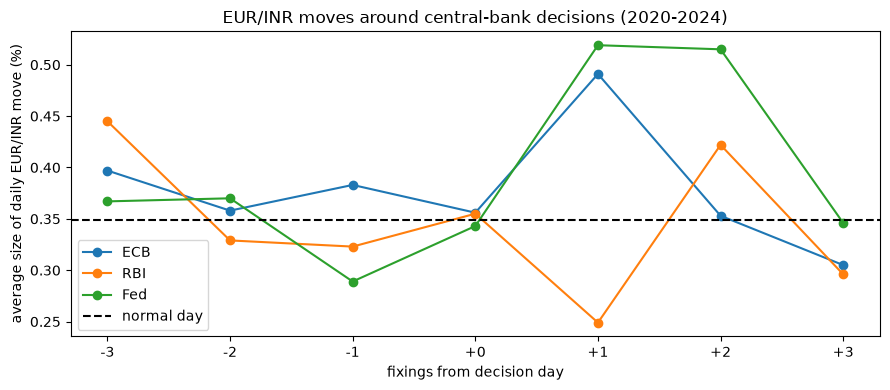

In [4]:
t2 = train.reset_index(drop=True)
normal = t2.loc[t2[EVENTS].sum(axis=1) == 0, "abs_chg"].mean()
BANKS = {"is_ecb_decision_day": "ECB", "is_rbi_decision_day": "RBI", "is_fomc_decision_day": "Fed"}
window = range(-3, 4)

rows = {}
for col, name in BANKS.items():
    pos = t2.index[t2[col] == 1]
    rows[name] = [t2["abs_chg"].reindex(pos + k).mean() for k in window]
around = pd.DataFrame(rows, index=[f"{k:+d}" for k in window]).round(3)
around.index.name = "fixings from decision day"
print(around)

ax = around.plot(marker="o", figsize=(9, 4))
ax.axhline(normal, color="black", linestyle="--", label="normal day")
ax.set_ylabel("average size of daily EUR/INR move (%)")
ax.set_title("EUR/INR moves around central-bank decisions (2020-2024)")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Calendar: weekday, day of month, special days

     days  move_size  direction  vs_week
Mon   197      0.374      0.118    0.022
Tue   203      0.333      0.014    0.015
Wed   204      0.335     -0.031   -0.020
Thu   204      0.329      0.041    0.020
Fri   197      0.392     -0.060   -0.037


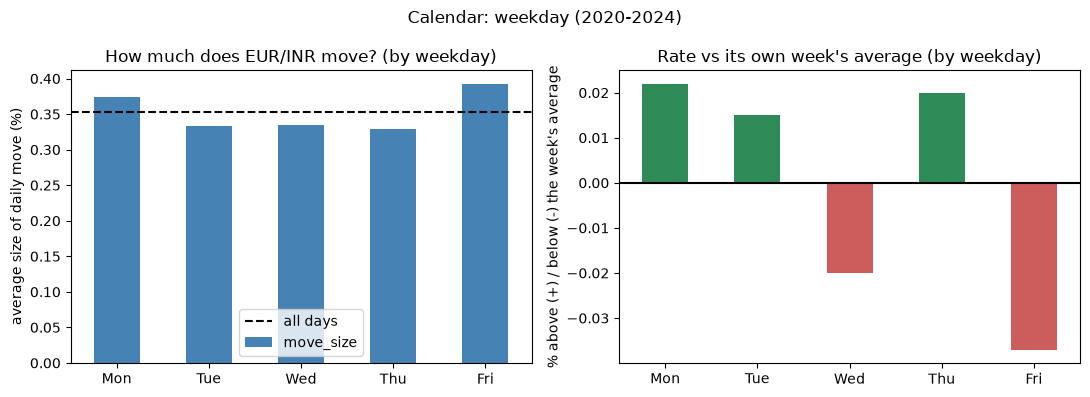

In [5]:
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri"]
t = train.copy()
t["week"] = t["date"].dt.to_period("W")
t["vs_week_pct"] = (t["eur_inr"] / t.groupby("week")["eur_inr"].transform("mean") - 1) * 100

by_day = t.groupby("weekday").agg(days=("abs_chg", "size"), move_size=("abs_chg", "mean"),
                                   direction=("chg_pct", "mean"), vs_week=("vs_week_pct", "mean")).round(3)
by_day.index = DAYS
print(by_day)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
by_day["move_size"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].axhline(t["abs_chg"].mean(), color="black", linestyle="--", label="all days")
axes[0].set_title("How much does EUR/INR move? (by weekday)")
axes[0].set_ylabel("average size of daily move (%)")
axes[0].legend()
by_day["vs_week"].plot(kind="bar", ax=axes[1],
                       color=["seagreen" if v > 0 else "indianred" for v in by_day["vs_week"]])
axes[1].axhline(0, color="black")
axes[1].set_title("Rate vs its own week's average (by weekday)")
axes[1].set_ylabel("% above (+) / below (-) the week's average")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.suptitle("Calendar: weekday (2020-2024)")
plt.tight_layout()
plt.show()

# day of month

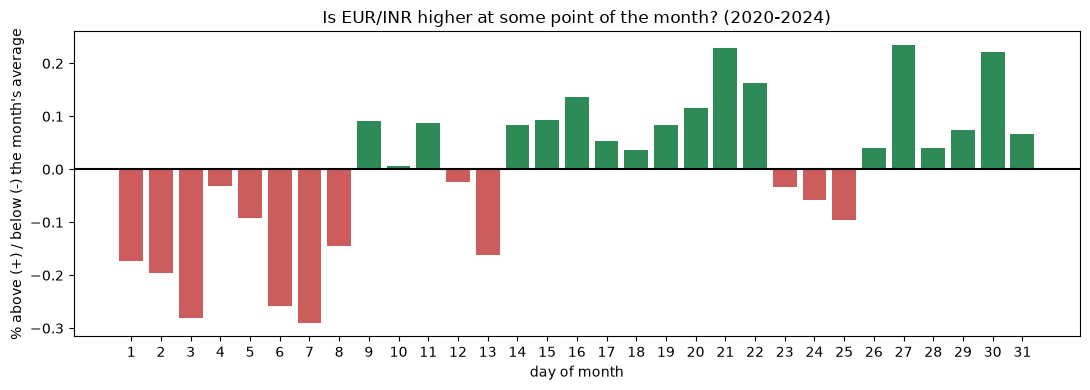

In [6]:
t["month_key"] = t["date"].dt.to_period("M")
t["vs_month_pct"] = (t["eur_inr"] / t.groupby("month_key")["eur_inr"].transform("mean") - 1) * 100
by_dom = t.groupby("day_of_month")["vs_month_pct"].mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(by_dom.index, by_dom.values,
       color=["seagreen" if v > 0 else "indianred" for v in by_dom.values])
ax.axhline(0, color="black")
ax.set_xticks(range(1, 32))
ax.set_xlabel("day of month")
ax.set_ylabel("% above (+) / below (-) the month's average")
ax.set_title("Is EUR/INR higher at some point of the month? (2020-2024)")
plt.tight_layout()
plt.show()

# Here each month is compared there own month avg. More like the smoothening way.

# method C

In [7]:
blocks = pd.cut(t["day_of_month"], [0, 3, 10, 20, 27, 31],
                labels=["1-3", "4-10", "11-20", "21-27", "28-31"])
check = t.groupby(blocks, observed=True).agg(days=("chg_pct", "size"),
                                              avg_daily_change=("chg_pct", "mean")).round(3)
print(check)

              days  avg_daily_change
day_of_month                        
1-3             97            -0.020
4-10           231             0.045
11-20          331             0.017
21-27          231             0.007
28-31          115             0.004


- Day of month: comparing each day with its own month's average suggests the rate is higher at
  month-end, but this is caused by the upward trend. Trend-free checks (average daily change,
  comparison with a local average) show no month-end effect. A small dip in the first 3 days of the
  month (about -0.1 %) appears in all methods; it is tiny (≈ ₹45 per €500) and may be noise.

# special days

In [8]:
FLAGS = {"is_payday_window": "Payday window", "is_in_holiday": "Indian holiday",
         "is_de_holiday": "German holiday", "is_december": "December",
         "is_india_fy_end": "India FY end", "is_diwali": "Diwali"}
rows = []
for col, name in FLAGS.items():
    on = t[col] == 1
    rows.append({"group": name, "days": int(on.sum()),
                 "move_size_on": t.loc[on, "abs_chg"].mean(),
                 "move_size_other": t.loc[~on, "abs_chg"].mean(),
                 "direction_on": t.loc[on, "chg_pct"].mean()})
print(pd.DataFrame(rows).set_index("group").round(3))

                days  move_size_on  move_size_other  direction_on
group                                                            
Payday window    141         0.363            0.351         0.028
Indian holiday    48         0.323            0.354        -0.044
German holiday    10         0.282            0.353         0.045
December          85         0.294            0.358         0.059
India FY end      20         0.356            0.352         0.093
Diwali             2         0.580            0.352         0.418


**Finding 3: the calendar has almost no effect on EUR/INR (2020–2024).**
- No useful "best weekday": the difference between the highest (Mon/Thu) and lowest day (Fri)
  is about 0.05 %, roughly ₹25 per €500, far below a normal daily move (0.33 %, ≈ ₹150).
- Mondays and Fridays move a little more (weekend news; US jobs reports on Fridays).
- Day of month: the rate looks higher late in the month, but this is mainly the upward trend
  over 2020–2024 (later days are naturally higher), not a real month-end effect.
- No payday effect. December is about 15 % calmer than other months (holiday season).
- Diwali (3 days) and German holidays (13 days) are too rare to judge.
- Shortlist: keep `weekday` and `is_december` (move size); drop or treat with care
  `is_diwali`, `is_payday_window`, `is_in_holiday`, `is_de_holiday`, `is_india_fy_end`.

## 4. Uncertainty: do spikes matter, and should GPR/EPU be smoothed?


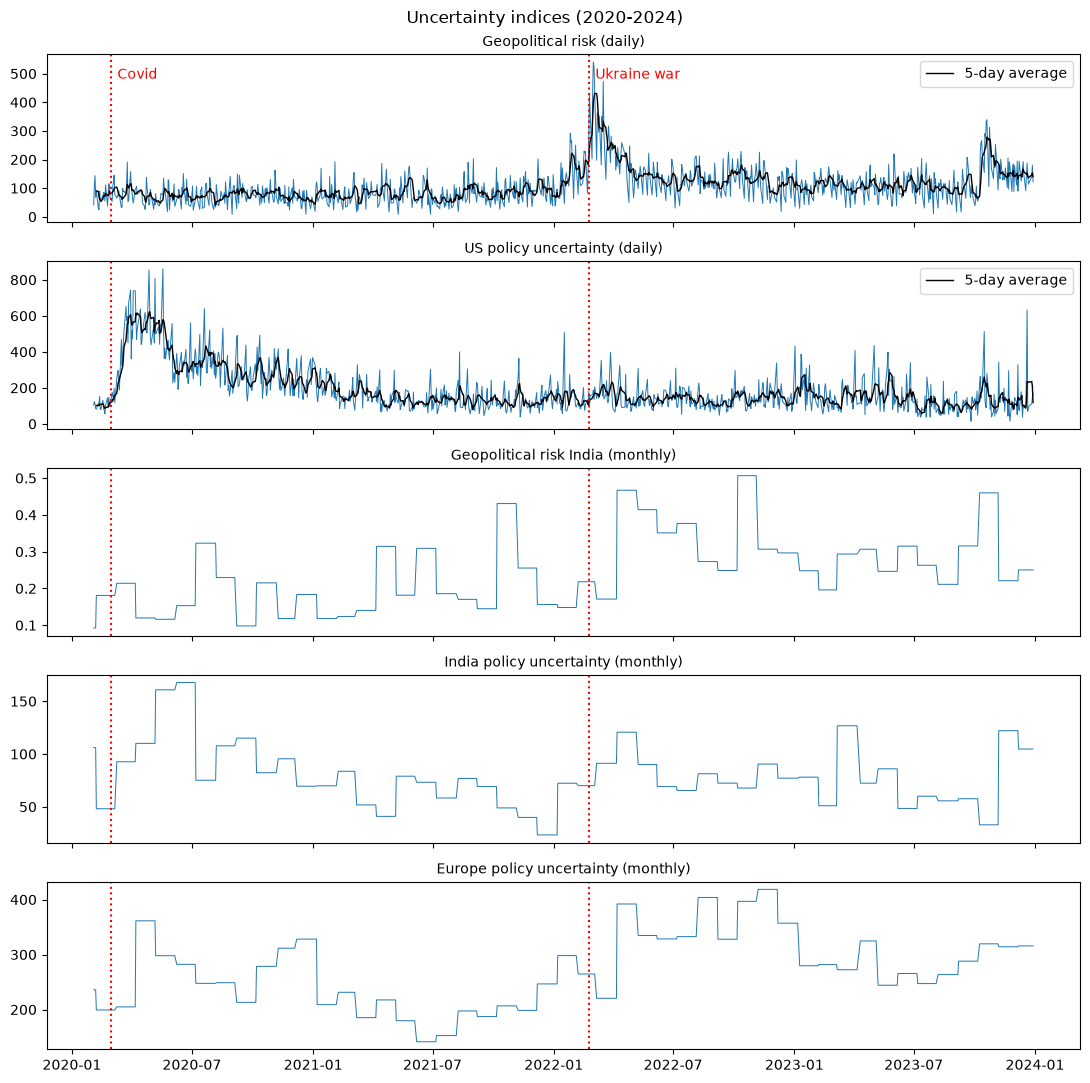

In [9]:
UNC = {"gpr": "Geopolitical risk (daily)", "us_epu": "US policy uncertainty (daily)",
       "gpr_india": "Geopolitical risk India (monthly)", "in_epu": "India policy uncertainty (monthly)",
       "eu_epu": "Europe policy uncertainty (monthly)"}
MARKS = {"2020-03-01": "Covid", "2022-02-24": "Ukraine war"}

fig, axes = plt.subplots(len(UNC), 1, figsize=(11, 11), sharex=True)
for ax, (col, name) in zip(axes, UNC.items()):
    ax.plot(train["date"], train[col], linewidth=0.7)
    if col in ("gpr", "us_epu"):
        ax.plot(train["date"], train[col].rolling(5).mean(), color="black", linewidth=1, label="5-day average")
        ax.legend(loc="upper right")
    for d in MARKS:
        ax.axvline(pd.Timestamp(d), color="red", linestyle=":")
    ax.set_title(name, fontsize=10)
axes[0].text(pd.Timestamp("2020-03-10"), axes[0].get_ylim()[1] * 0.85, "Covid", color="red")
axes[0].text(pd.Timestamp("2022-03-05"), axes[0].get_ylim()[1] * 0.85, "Ukraine war", color="red")
plt.suptitle("Uncertainty indices (2020-2024)")
plt.tight_layout()
plt.show()

           1 lowest      2      3      4  5 highest
gpr           0.313  0.356  0.356  0.365      0.373
us_epu        0.336  0.353  0.358  0.351      0.365
gpr_india     0.337  0.301  0.381  0.358      0.385
in_epu        0.353  0.315  0.321  0.412      0.365
eu_epu        0.339  0.308  0.339  0.334      0.447


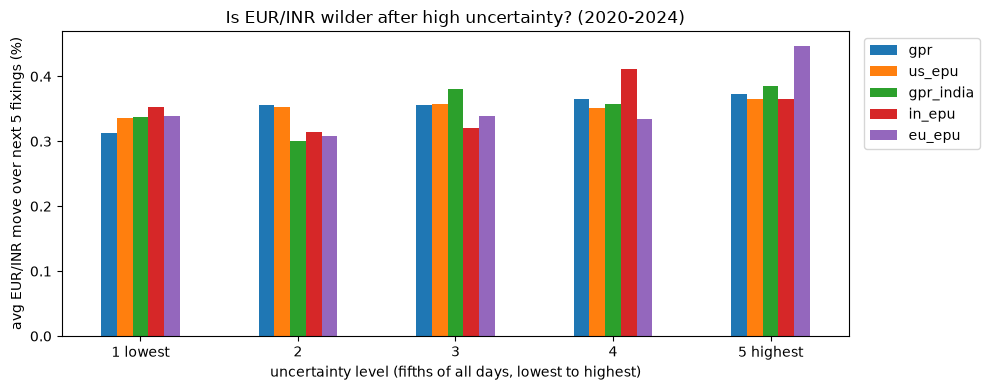

In [10]:
t = train.copy()
t["next5_move"] = t["abs_chg"][::-1].rolling(5).mean()[::-1].shift(-1)   # avg move over the next 5 fixings

rows = []
for col in UNC:
    level = pd.qcut(t[col], 5, labels=["1 lowest", "2", "3", "4", "5 highest"])
    rows.append(t.groupby(level, observed=True)["next5_move"].mean().rename(col))
by_level = pd.DataFrame(rows).round(3)
print(by_level)

ax = by_level.T.plot(kind="bar", figsize=(10, 4))
ax.set_xlabel("uncertainty level (fifths of all days, lowest to highest)")
ax.set_ylabel("avg EUR/INR move over next 5 fixings (%)")
ax.set_title("Is EUR/INR wilder after high uncertainty? (2020-2024)")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

After the most uncertain fifth of days, EUR/INR moves more over the next 5 fixings for US EPU (+18 %),
Europe EPU (+20 %) and India GPR (+15 %). World GPR and India EPU show no clear pattern.
Caveat: very high values cluster in a few special periods (Covid 2020, late 2022, late 2024).

# does smoothing help? What is smoothing in normal terms? : 

In [11]:
rows = []
for col in ["gpr", "us_epu"]:
    versions = {"raw (1 day)": t[col],
                "5-day average": t[col].rolling(5).mean(),
                "20-day average": t[col].rolling(20).mean()}
    for vname, v in versions.items():
        rows.append({"index": col, "version": vname,
                     "link_with_next5_move": v.corr(t["next5_move"], method="spearman")})
smooth = pd.DataFrame(rows).pivot(index="version", columns="index", values="link_with_next5_move").round(3)
print(smooth)

index             gpr  us_epu
version                      
20-day average  0.238   0.042
5-day average   0.217   0.034
raw (1 day)     0.143   0.061


**Finding 4: uncertainty says a little about how much EUR/INR moves, but the result is not stable (train 2020–2023).**
- After the most uncertain fifth of days, EUR/INR moves more over the next 5 fixings for
  [fill in from 4b: which indices and by how much].
- World GPR: the rank correlation with the next 5 fixings' moves rises from 0.14 (raw) to 0.22 (5-day)
  and 0.24 (20-day average), so smoothing helps.
- US EPU: almost no link (0.03–0.06 in every version).
- In the earlier run with 2024 included, the picture was reversed (US EPU 0.10, GPR 0.06). One volatile
  period (late 2024) can change the conclusion, so the 2024 validation year decides which index to keep.
- Caveat: very uncertain days cluster in a few special periods (Covid 2020, 2022), which were volatile anyway.
  This is about the size of moves, not their direction.
> **Rerun 24 Nov:** rows from 1 Feb 2020, train 2020–2023 (2024 = validation).
> Events (Findings 1–2) and uncertainty (Finding 4) were rechecked. The calendar numbers in Finding 3
> are still from the earlier 2020–2024 run; the conclusions (keep weekday and December) are unchanged in the plan.

## 5. Do my columns overlap? (correlation heatmap)

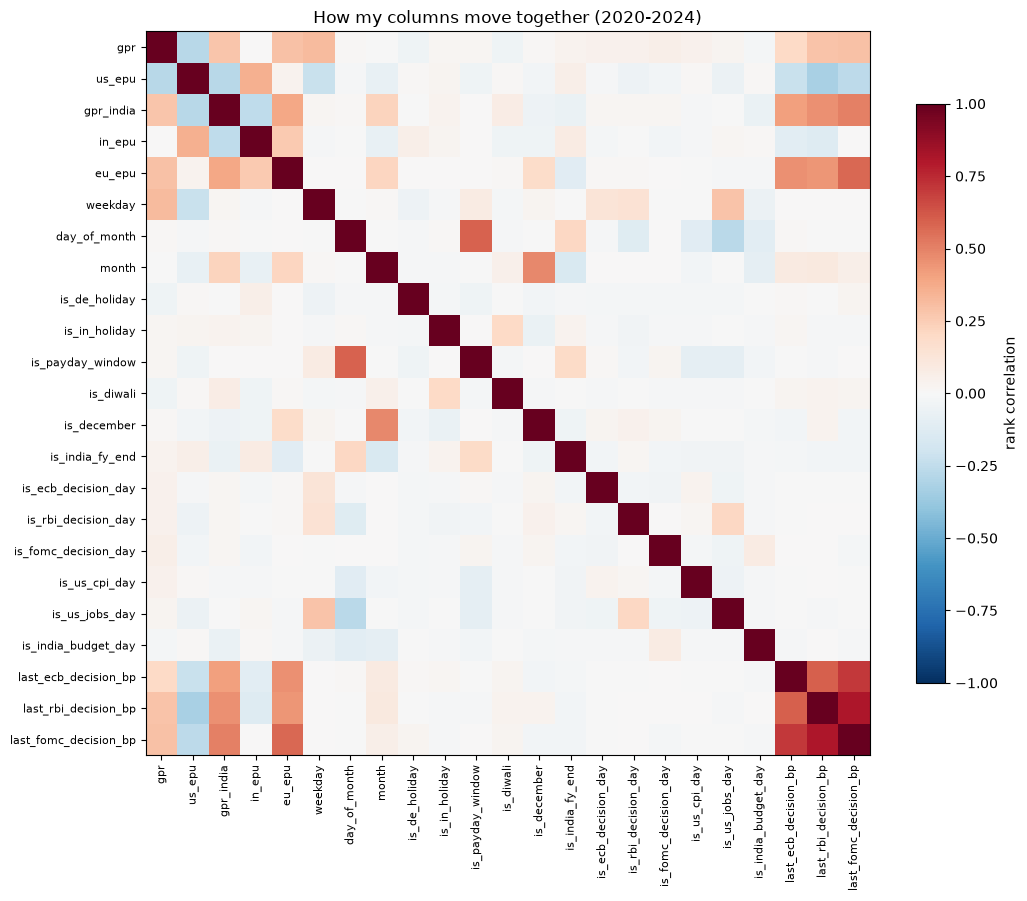

             level_0               level_1  corr
last_rbi_decision_bp last_fomc_decision_bp  0.81
last_ecb_decision_bp last_fomc_decision_bp  0.71
last_ecb_decision_bp  last_rbi_decision_bp  0.60
        day_of_month      is_payday_window  0.59
              eu_epu last_fomc_decision_bp  0.58
           gpr_india last_fomc_decision_bp  0.50


In [12]:
import numpy as np

corr = train[MY_COLS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(MY_COLS)))
ax.set_xticklabels(MY_COLS, rotation=90, fontsize=8)
ax.set_yticks(range(len(MY_COLS)))
ax.set_yticklabels(MY_COLS, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="rank correlation")
ax.set_title("How my columns move together (2020-2024)")
plt.tight_layout()
plt.show()

# list the strongest pairs
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("corr").reset_index())
strong = pairs[pairs["corr"].abs() >= 0.5].sort_values("corr", key=abs, ascending=False)
print(strong.round(2).to_string(index=False))

**Finding 5: my columns do not duplicate each other (2020–2024).**
- No pair reaches the 0.95 near-duplicate threshold; 79 % of pairs are almost unrelated (|r| < 0.1).
- The last ECB, RBI and Fed decisions move together (0.53–0.75): all three cut in 2020 and hiked
  in 2022–23. Keep all three for now; feature selection decides later.
- Links by construction: day_of_month vs is_payday_window (0.59), month vs is_december (0.48).
- GPR vs US EPU is slightly negative (-0.28): they measure different kinds of worry (wars vs economic policy).
- Weekday artefacts: GPR is much lower on Monday rows (Sunday news, median 64 vs ~118), while US EPU
  is highest on Mondays.
- RBI decisions and US jobs reports fell on the same day 11 times, so their effects in Finding 2
  partly overlap.
- Links between decision sizes and uncertainty (e.g. gpr_india vs last Fed decision, 0.47) reflect
  timing (2022–23), not cause and effect.

## 6. Feature shortlist (my columns)

| Column | Decision | Reason (finding) |
|---|---|---|
| `is_ecb_decision_day`, `is_fomc_decision_day`, `is_us_cpi_day`, `is_us_jobs_day` | **keep** | Announced after the fixing; the next move is 26–51 % larger than normal (F2). Scheduled, so known in advance |
| `is_rbi_decision_day` | **keep** | Announced before the fixing; bumpier same day, calmer next day (F2) |
| `is_india_budget_day` | optional | Only 6 budgets; borderline evidence (F2) |
| `last_ecb/rbi/fomc_decision_bp` | **keep, as hike / hold / cut** | Real information, but the three overlap (0.53–0.75) (F5) |
| `us_epu` | **keep, 7-calendar-day average** | Steadiest uncertainty signal (+18 %) (F4); Sunday artefact (F5) |
| `eu_epu` | **keep** | +20 % bumpier after the most uncertain fifth (F4) |
| `gpr_india` | **keep** | +15 % bumpier in the top two fifths (F4) |
| `gpr` | transform: 7-calendar-day average, low priority | No clear pattern (F4); low on Sundays/Mondays (F5) |
| `in_epu` | optional, low priority | No pattern (F4) |
| `weekday` | **keep** | Mondays and Fridays are bumpier (F3) |
| `is_december` | **keep** | December is about 15 % calmer (F3) |
| `day_of_month` | optional | Only a small dip in days 1–3 (F3) |
| `month` | drop | Covered by `is_december` |
| `is_payday_window` | drop | No effect (F3) |
| `is_in_holiday`, `is_india_fy_end` | drop | No clear effect (F3) |
| `is_de_holiday`, `is_diwali` | drop | Too rare (13 and 3 days) (F3) |

**New features to build (from the base file and `events_clean.csv`):**
- `days_to_*`: countdown to the next **scheduled** ECB, RBI, Fed, CPI and jobs date (built from
  `events_clean.csv`, never from the flags, so surprise meetings are not foreseen).
- `event_in_next_5d`: a scheduled announcement within the 5-day horizon.
- `us_epu_7d`, `gpr_7d`: averages over the last 7 calendar days (removes the Sunday artefact).

**Important:** these features help predict **how much** EUR/INR moves, not **whether it goes up or down**.